Dataset:


,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


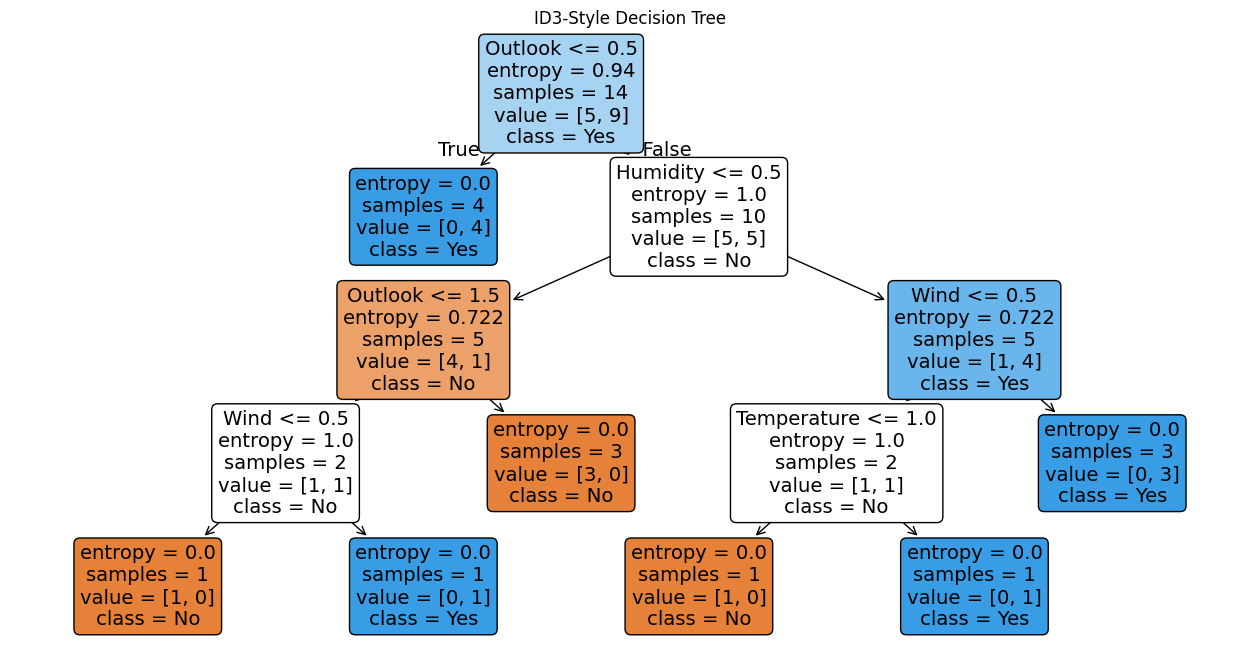

New sample:


,Outlook,Temperature,Humidity,Wind
0,Sunny,Cool,Normal,Weak


Predicted class: Yes
Training accuracy: 100.00%


In [1]:

# EXPERIMENT 3: ID3 DECISION TREE
# Run this cell in Google Colab

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OrdinalEncoder

# Step 1: Create the Play Tennis dataset
data = {
    "Outlook": ["Sunny","Sunny","Overcast","Rain","Rain","Rain",
                "Overcast","Sunny","Sunny","Rain","Sunny","Overcast",
                "Overcast","Rain"],
    "Temperature": ["Hot","Hot","Hot","Mild","Cool","Cool","Cool",
                    "Mild","Cool","Mild","Mild","Mild","Hot","Mild"],
    "Humidity": ["High","High","High","High","Normal","Normal","Normal",
                 "High","Normal","Normal","Normal","High","Normal","High"],
    "Wind": ["Weak","Strong","Weak","Weak","Weak","Strong","Strong",
             "Weak","Weak","Weak","Strong","Strong","Weak","Strong"],
    "PlayTennis": ["No","No","Yes","Yes","Yes","No","Yes","No",
                   "Yes","Yes","Yes","Yes","Yes","No"]
}

df = pd.DataFrame(data)
print("Dataset:")
display(df)

# Step 2: Encode categorical values
X = df.drop("PlayTennis", axis=1)
y = df["PlayTennis"]

encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X)

# Step 3: Build an entropy-based decision tree
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)
model.fit(X_encoded, y)

# Step 4: Display the decision tree
plt.figure(figsize=(16, 8))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)
plt.title("ID3-Style Decision Tree")
plt.show()

# Step 5: Predict a new sample
new_sample = pd.DataFrame([{
    "Outlook": "Sunny",
    "Temperature": "Cool",
    "Humidity": "Normal",
    "Wind": "Weak"
}])

new_encoded = encoder.transform(new_sample)
prediction = model.predict(new_encoded)[0]

print("New sample:")
display(new_sample)
print("Predicted class:", prediction)

# Step 6: Display training accuracy
accuracy = model.score(X_encoded, y) * 100
print(f"Training accuracy: {accuracy:.2f}%")
